# BIOINF 580 - HW 02

### Due Sunday, Oct. 25 at 11:59pm

---

## General Instructions

- Please **answer all questions** in this report with clear, written responses and complete sentences.

- Provide **comments for all code blocks**, so that readers can easily understand the purpose and logic of each step. 

- Each plot must have a **descriptive title, axis labels with units (when applicable), and a legend (when appropriate)** to ensure clarity.  

- **Collaboration and AI policy:** [INSTRUCTOR: replace with the course policy on collaboration and generative-AI use]. Cite any help you received in your references.

- Provide any **references** (textbooks, articles, online sources, etc.) that you used to prepare your report and code.

- Mute any **unnecessary code output** using `#` to comment out print/debug lines or other non-essential outputs, so the notebook remains clean and readable.

---

## Submission Requirement:  

- Submit the Jupyter notebook (`.ipynb`) file with all code and the written report included.  

- Name the file as: `HW02_YourUniqueName.ipynb`

- **Before submitting, restart the kernel and run all cells top to bottom** (*Kernel → Restart & Run All*). Your notebook must run without errors and the saved outputs must match your written answers. Notebooks that do not run cleanly lose points.

---

## 0. Environment Setup and Getting Started

Before starting this homework, please make sure you are in the correct Python environment.

1. **Activate the conda environment** (in your terminal or Anaconda Prompt):  
   - If you have already created the `bioinf580` environment, activate it using:
      ```bash
      conda activate bioinf580
      ```
   
   - If you haven’t set it up yet, please refer to *Lab01.ipynb* for detailed setup instructions.

2. **Select the Jupyter kernel**:
   - When this notebook is open, go to the top-right corner of JupyterLab/Notebook and choose **bioinf580** as the kernel. 
   
   - Refer to *Lab01.ipynb* if you have not linked the kernel yet.

3. **Clone the Higuchi Fractal Dimension repository**:
   - Confirm that the repository exists in your working directory. Example:
      ```bash
      git clone https://github.com/inuritdino/HiguchiFractalDimension.git
      ```

4. **Ensure all required packages are installed**:
   - Please make sure the following Python packages are available in your environment: 
      - `pandas` 
      - `numpy`
      - `scipy`
      - `scikit-learn`
      - `matplotlib`
      - `pywavelets`
      - `HiguchiFractalDimension` (from the cloned GitHub repo)
   - The course provides a pinned `environment.yml` (see Canvas). The easiest way to get a matching environment is:
      ```bash
      conda env create -f environment.yml
      ```
   - Alternatively, install any missing packages using:
      ```bash
      conda install pandas numpy scipy scikit-learn matplotlib pywavelets
      ```

5. **Check required packages**:
   - Run the code cell below to verify that all necessary libraries have been installed successfully.

## AI Disclosure

Claude was used to draft the code and refine some of the report. I verified the AI-generated information.

In [1]:
## Check required packages

import pandas as pd
import numpy as np
import scipy
import sklearn
import matplotlib
import pywt

import sys
sys.path.append("../../lab/lab2")  # adjust if the repo is cloned elsewhere
import HiguchiFractalDimension as hfd

print("✅ Environment ready — all required packages are installed and importable.")


✅ Environment ready — all required packages are installed and importable.


## Part I (20 pts) - K-means Clustering on 2D Data

<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 1.1 (2 pts) Load 2D Data

Load the file **`data_2D.csv`** from **`Assignments > Homework assignments > HW 02`** on Canvas.

This file contains **500 × 2** numeric values (two columns, **no header**).  
Read the file and save it in the variable **`X_2D`**.

</div>

In [2]:
# (Your code for Section 1.1 goes here)
# read file as dataframe
X_2D = pd.read_csv("data_2D.csv", header=None)

<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 1.2 (3 pts) Initial Plot & Observations

Create a **scatter plot** of the two-dimensional data in **`X_2D`** (use column 0 on the x-axis and column 1 on the y-axis).  
Briefly **describe any visible patterns** and **estimate how many clusters** you can identify from the plot.

</div>

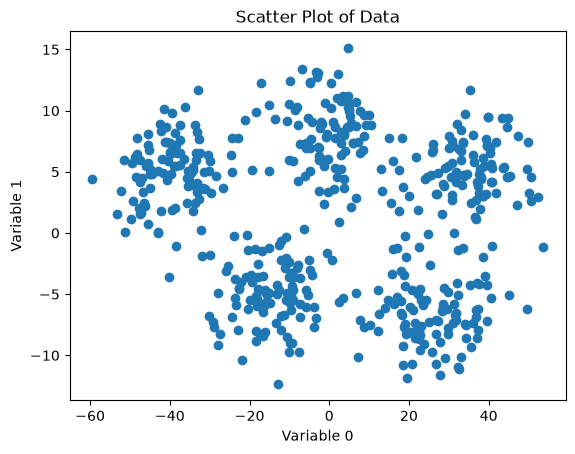

In [3]:
# (Your code for Section 1.2 goes here)
import matplotlib.pyplot as plt
# plot scatter plot
plt.scatter(x=X_2D[0], y=X_2D[1])
plt.title("Scatter Plot of Data")
plt.xlabel("Variable 0")
plt.ylabel("Variable 1")
plt.show()


(Write your report for Section 1.2 here)

The points seem to cluster into 5 groups which seem to have somewhat of a spherical distribution if we do not take units into account.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 1.3 (5 pts) Implement K-Means (scikit-learn)

Read the KMeans docs: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

Implement K-Means on **z-scored** features. **You must set** (and state them in your code):
- **`k`** — number of clusters
- **`random_state`** — a fixed integer, so your results are reproducible
- **`n_init`** — number of random restarts (set it explicitly, e.g. `10`; do not rely on the default, which changed between scikit-learn versions)

Fit the model and **produce a scatter plot** of the data colored by cluster label.

</div>

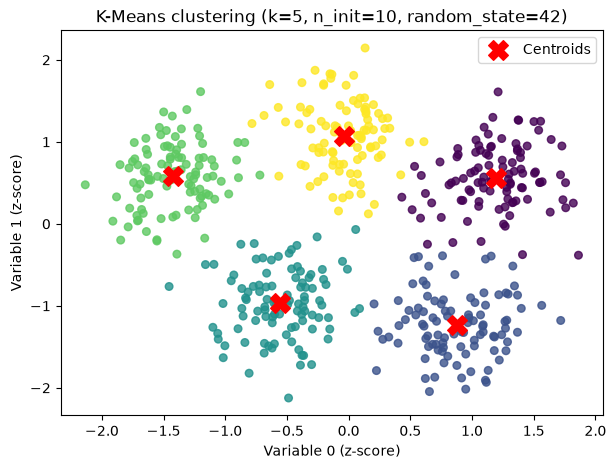

In [4]:
# (Your code for Section 1.3 goes here)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# --- Parameters (set explicitly) ---
k = 5              # number of clusters
random_state = 42  # fixed seed for reproducibility
n_init = 10        # number of random restarts (set explicitly; default changed across versions)

# --- Z-score the features (mean 0, SD 1 per column) ---
X_z = StandardScaler().fit_transform(X_2D)

# --- Fit K-Means ---
kmeans = KMeans(n_clusters=k, random_state=random_state, n_init=n_init)
labels = kmeans.fit_predict(X_z)

# --- Scatter plot colored by cluster ---
plt.figure(figsize=(7, 5))
plt.scatter(X_z[:, 0], X_z[:, 1], c=labels, cmap="viridis", s=30, alpha=0.8)
plt.scatter(*kmeans.cluster_centers_[:, :2].T, c="red", marker="X", s=200, label="Centroids")
plt.xlabel(f"Variable 0 (z-score)")
plt.ylabel(f"Variable 1 (z-score)")
plt.title(f"K-Means clustering (k={k}, n_init={n_init}, random_state={random_state})")
plt.legend()
plt.show()

<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 1.4 (5 pts) Choose $k$ with Davies–Bouldin & Calinski–Harabasz

Implement the **Davies–Bouldin (DB)** and **Calinski–Harabasz (CH)** criteria using scikit-learn, test $k=2 \dots 10$, and decide the **best $k$**.

- **DB**: **lower is better**  
- **CH**: **higher is better**

**Tasks**
1) Z-score the data.  
2) For each $k \in \{2,\dots,10\}$: fit `KMeans` (with a fixed `random_state` and explicit `n_init`, as in 1.3), compute DB and CH.  
3) Plot DB and CH vs $k$.  
4) Pick a best $k$ (justify briefly).

</div>

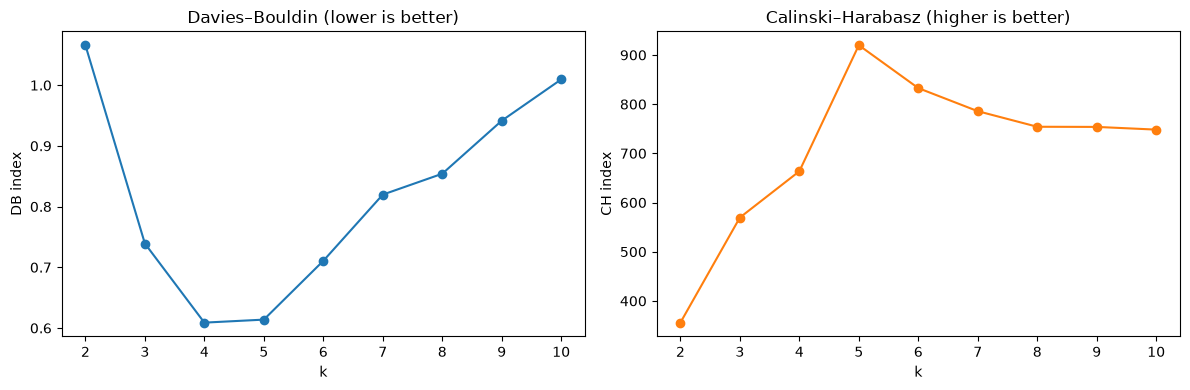

Best k by DB (min): 4  (DB = 0.609)
Best k by CH (max): 5  (CH = 919.9)


In [5]:
# (Your code for Section 1.4 goes here)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score


# 1) Z-score the data
X_z = StandardScaler().fit_transform(X_2D)

random_state = 42
n_init = 10
k_values = range(2, 11)

# 2) Fit K-Means for each k and compute DB and CH
db_scores, ch_scores = [], []
for k in k_values:
    labels = KMeans(n_clusters=k, random_state=random_state, n_init=n_init).fit_predict(X_z)
    db_scores.append(davies_bouldin_score(X_z, labels))
    ch_scores.append(calinski_harabasz_score(X_z, labels))

# 3) Plot DB and CH vs k
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, db_scores, "o-")
axes[0].set(title="Davies–Bouldin (lower is better)", xlabel="k", ylabel="DB index")
axes[1].plot(k_values, ch_scores, "o-", color="tab:orange")
axes[1].set(title="Calinski–Harabasz (higher is better)", xlabel="k", ylabel="CH index")
for ax in axes:
    ax.set_xticks(list(k_values))
plt.tight_layout()
plt.show()

# 4) Best k according to each criterion
best_k_db = list(k_values)[int(np.argmin(db_scores))]
best_k_ch = list(k_values)[int(np.argmax(ch_scores))]
print(f"Best k by DB (min): {best_k_db}  (DB = {min(db_scores):.3f})")
print(f"Best k by CH (max): {best_k_ch}  (CH = {max(ch_scores):.1f})")

(Write your report for Section 1.4 here)

k=5 seems to be the best choice of k. CH shows index is best at k=5 whereas DB shows index is best at k=4. However, the difference between k=4 and k=5 is minimal so k=5 seems to be a good choice based on both criteria.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 1.5 (5 pts) Geometry & Distance Metric

1. Re-plot **`X_2D`** as a scatter plot using **equal axis scales**: set the **same limits** on x and y **and** use an equal aspect ratio (`ax.set_aspect("equal")`).
2. Based on the geometry you observe, decide whether **Euclidean** distance is appropriate for this data. If not, state which metric (or which kind of algorithm) would be better **and explain why**.
3. scikit-learn's `KMeans` supports **Euclidean distance only**. Fit **one alternative** that is better suited to the geometry you observe — for example `DBSCAN`, `GaussianMixture`, or `AgglomerativeClustering` — plot its result, and compare it to your K-Means result from 1.3 in **1–2 sentences** (what does it get right or wrong that K-Means does not?).

*Hint:* Use matching limits for both axes (e.g., `xlim(a, b)` and `ylim(a, b)`).

</div>

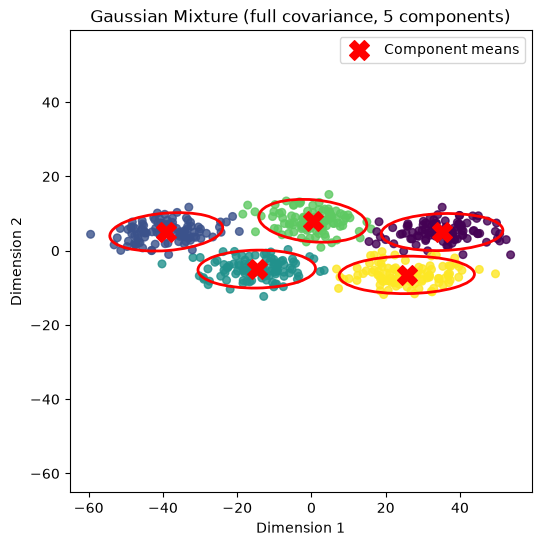

In [6]:
# (Your code for Section 1.5 goes here)
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture

# --- Parameters (set explicitly) ---
n_components = 5
random_state = 42
n_init = 10

gmm = GaussianMixture(n_components=n_components, covariance_type="full",
                      random_state=random_state, n_init=n_init)
gmm_labels = gmm.fit_predict(X_2D)

# --- Plot with equal axis scales ---
lo, hi = np.min(X_2D), np.max(X_2D)
pad = 0.05 * (hi - lo)
lims = (lo - pad, hi + pad)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X_2D[0], X_2D[1], c=gmm_labels, cmap="viridis", s=30, alpha=0.8)

# Draw each component's 2-standard-deviation ellipse
for mean, cov in zip(gmm.means_, gmm.covariances_):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
    width, height = 2 * 2 * np.sqrt(vals[::-1])   # 2 SD on each side
    ax.add_patch(Ellipse(mean, width, height, angle=angle,
                         fill=False, edgecolor="red", linewidth=2))
ax.scatter(*gmm.means_.T, c="red", marker="X", s=200, label="Component means")

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_xlabel("Dimension 1")
ax.set_ylabel("Dimension 2")
ax.set_title(f"Gaussian Mixture (full covariance, {n_components} components)")
ax.legend()
plt.show()


(Write your report for Section 1.5 here)

Plotting variables 0 and 1 on equal axes shows that the clusters are elongated rather than spherical, so K-Means is poorly suited here. It assigns points by Euclidean distance and implicitly assumes round, similarly sized clusters. A full-covariance Gaussian Mixture Model learns a separate shape and orientation for each cluster, so its boundaries follow the elliptical structure of the data. GMM also doesn’t require z-scoring, so it can be fit on the original units. This makes it more interpretable: a z-score of 0 means only “average in this sample,” whereas raw values carry clinical meaning (e.g., a given symptom severity score).



## Part II (20 pts) - ECG Signal Entropy

<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 2.1 (2 pts) Load ECG Data

Load the file **`ecg_data_hw2.csv`** from **`Assignments > Homework assignments > HW 02`** on Canvas.

The file contains a single-column ECG signal with the sampling rate of **250 Hz** to be used in this assignment.  
Read the file and extract the ECG data as a NumPy array, and store it in the variable **`ecg_raw`**.

</div>

In [7]:
# (Your code for Section 2.1 goes here)
ecg_raw = pd.read_csv("ecg_data_hw2.csv", header=None)[0].to_numpy(dtype=float)

<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 2.2 (3 pts) Apply Bandpass Filtering to Remove Noise  

The raw ECG signal contains noise at both high and low frequencies. Apply a **zero-phase Butterworth bandpass filter** (order 4, implemented with `scipy.signal.butter` and `scipy.signal.filtfilt`) with cutoff frequencies of **5 Hz** and **50 Hz** at the sampling rate **fs = 250 Hz**.

Store the filtered signal in a variable named `ecg_filtered`, and plot both the raw and filtered ECG signals for comparison over the **first 10 seconds** (x-axis in **seconds**, 0–10 s).

Then, in the response cell below, write **1–2 sentences** on what the 5 Hz high-pass edge removes or attenuates (e.g., baseline wander) and why that matters for the later entropy and wavelet analyses.

</div>

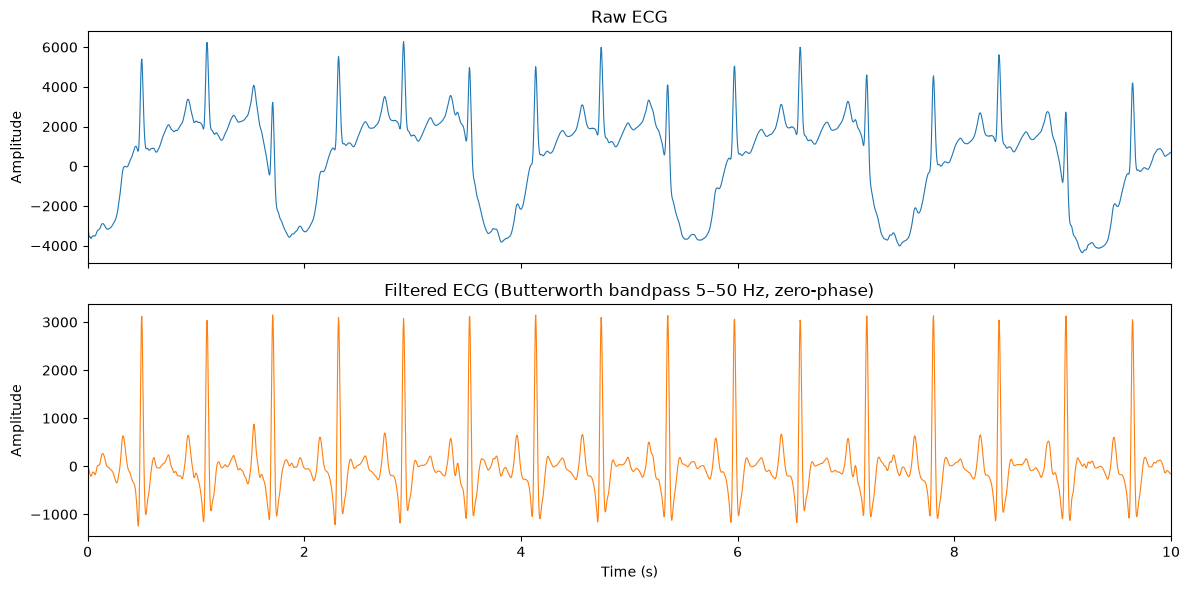

In [8]:
# (Your code for Section 2.2 goes here)
from scipy.signal import butter, filtfilt

fs = 250                 # sampling rate (Hz)
lowcut, highcut = 5, 50  # cutoff frequencies (Hz)
order = 4

# Design 4th-order Butterworth bandpass and apply zero-phase filtering
b, a = butter(order, [lowcut, highcut], btype="bandpass", fs=fs)
ecg_filtered = filtfilt(b, a, ecg_raw)

# Plot the first 10 seconds
n = int(10 * fs)
t = np.arange(n) / fs

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t, ecg_raw[:n], linewidth=0.8)
axes[0].set(title="Raw ECG", ylabel="Amplitude")
axes[1].plot(t, ecg_filtered[:n], linewidth=0.8, color="tab:orange")
axes[1].set(title="Filtered ECG (Butterworth bandpass 5–50 Hz, zero-phase)",
            xlabel="Time (s)", ylabel="Amplitude")
axes[1].set_xlim(0, 10)
plt.tight_layout()
plt.show()



(Write your report for Section 2.2 here)

The large sub-0.5 Hz component most likely reflects DC offset, baseline wander, or respiration, which typically falls around 0.15–0.4 Hz (Task Force of the ESC/NASPE, 1996, Circulation). This matters because we are mostly concerned with the QRS complex which is a major feature of interest in ECG analysis.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 2.3 (5 pts) Entropy Function Completion

Complete the `renyi_entro` function to include the definitions of **Shannon** and **Hartley** entropy.

**Important:** the starter code rounds values with `np.round(x, -2)` (to the nearest hundred). This is only meaningful for ECG stored in **ADC units** (amplitudes in the hundreds to thousands). If the data were in millivolts (±a few mV) every value would round to 0 and the entropy would collapse to 0. After you complete the function, run the **self-check cell** below before using it on the ECG.

</div>

In [9]:
# (Starter code for Section 2.3)

import numpy as np

def renyi_entro(data, alpha):
    """
    Compute Rényi entropy (base-2) with special cases:
      - alpha = 0  → Hartley entropy: log2(number of distinct states)
      - alpha = 1  → Shannon entropy: -sum p * log2(p)
      - otherwise  → Rényi entropy: (1 / (1 - alpha)) * log2(sum p^alpha)
    """
    # Ensure 1D numeric array
    x = np.asarray(data, dtype=float).ravel()

    # Round values for binning consistency
    x = np.round(x, -2)

    # Compute probability of each unique value
    unique_vals, counts = np.unique(x, return_counts=True)
    P = counts.astype(float) / x.size
    P = P[P > 0]  # remove zero probabilities

    # ----------------------------
    # TODO: Complete the sections below
    # ----------------------------
    if alpha == 0:
        # Hartley entropy: log2 of the number of distinct states
        y = np.log2(len(P))

    elif alpha == 1:
        # Shannon entropy: -sum p * log2(p)
        y = -np.sum(P * np.log2(P))

    else:
        # General Rényi entropy (provided)
        y = (1.0 / (1.0 - alpha)) * np.log2(np.sum(P ** alpha))

    return float(y)


##### 2.3 self-check (not graded)

Run this cell after completing `renyi_entro`. The test signal has 8 equally likely amplitude levels (multiples of 100), so **every** order of Rényi entropy must equal $\log_2 8 = 3$ bits. If an assertion fails, fix your function before moving on.

In [10]:
# 2.3 self-check: 8 equally likely states -> entropy = log2(8) = 3 bits for any alpha
test = (np.arange(8) * 100).repeat(100)
for a in [0, 0.5, 1, 2]:
    val = renyi_entro(test, a)
    assert np.isclose(val, 3.0), f"alpha={a}: expected 3.0, got {val}"
print("✅ renyi_entro passes the self-check.")

✅ renyi_entro passes the self-check.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

#### 2.4 (5 pts) Calculate Shannon entropy over time (4-s window, 1-s step)

Calculate the Shannon entropy of the filtered ECG (`ecg_filtered`) using a sliding window of **4 seconds** with a **1-second** step, and plot the **filtered ECG** (top) and **entropy** (bottom) in two stacked subplots with a **shared time axis in seconds**.

Mark the **asystole onset** (the signal flat-lines at **295 s**) with a **vertical line** on both subplots and label it in the legend.

Use the window **center time** as the time stamp of each entropy value. In the response cell below, write **1–2 sentences** describing how the entropy trace behaves before vs. after the marked onset.

</div>

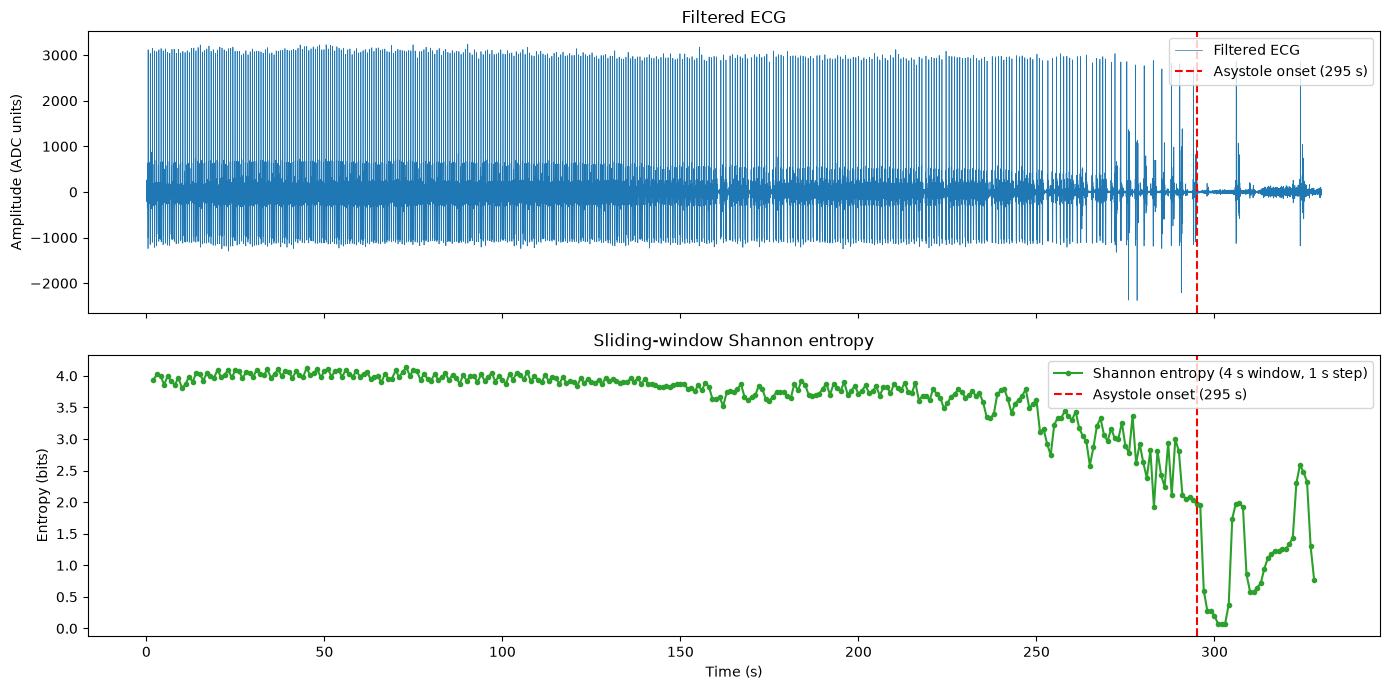

In [11]:
# (Your code for Section 2.4 goes here)

fs = 250
win = 4 * fs        # 4-second window (1000 samples)
step = 1 * fs       # 1-second step (250 samples)
asystole_t = 295    # asystole onset (s)

# Sliding-window Shannon entropy
starts = np.arange(0, len(ecg_filtered) - win + 1, step)
entropy = np.array([renyi_entro(ecg_filtered[s:s + win], alpha=1) for s in starts])
t_entropy = (starts + win / 2) / fs   # time stamp = window center (s)

t_ecg = np.arange(len(ecg_filtered)) / fs

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(t_ecg, ecg_filtered, linewidth=0.5, label="Filtered ECG")
axes[0].set(title="Filtered ECG", ylabel="Amplitude (ADC units)")

axes[1].plot(t_entropy, entropy, "o-", markersize=3, color="tab:green",
             label="Shannon entropy (4 s window, 1 s step)")
axes[1].set(title="Sliding-window Shannon entropy", xlabel="Time (s)", ylabel="Entropy (bits)")

for ax in axes:
    ax.axvline(asystole_t, color="red", linestyle="--", linewidth=1.5, label="Asystole onset (295 s)")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


(Write your report for Section 2.4 here)

There seems to be a gradual decrease in entropy before the asystole onset, followed by a sharp drop in entropy after the onset.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

##### 2.5 (5 pts) Interpretation

Is there a noticeable difference between the **healthy** and **asystole** sections of the ECG signal?  
Is this difference expected? Explain **why or why not**, based on the physiological meaning of the signals and their corresponding entropy patterns.

**Before you compute 2.4**, write down (in the response cell for 2.5) your **hypothesis**: do you expect Shannon entropy to *increase* or *decrease* during asystole, and why? Then compare with what you observe, and explain any mismatch.

</div>

(Write your report for Section 2.5 here)

Yes, there is a noticeable difference between healthy and asystole sections of the ECG signal. This difference is expected as a healthy ECG reflects ongoing depolarization and repolarization of the heart, producing a varied amplitude distribution, whereas asystole is the absence of cardiac electrical activity, leaving only a near-constant baseline with very little variability.

Accordingly, I expect Shannon entropy to decrease during asystole as there is little variability in the signal, meaning probability of certain signal increases and probability of other signals decrease.

The plot seems to support this hypothesis.


## Part III (60 pts) - Feature Extraction & 2-Cluster Clustering for Asystole Detection

Use a **sliding window** on the **filtered ECG signal** (same as in HW01 and Part II):  
- **Window length:** 4 seconds (minimum required to detect asystole)  
- **Sliding interval:** 1 second  
- **Example:** analyze seconds **0–4**, then **1–5**, **2–6**, and so on  
- You will obtain **327 sliding windows** in total. Report the exact number you obtain as `n_windows`.

Extract features from each sliding window using **Higuchi Fractal Dimension (HFD)**, **Continuous Wavelet Transform (CWT)**, and **Discrete Wavelet Transform (DWT)** **separately**, and **cluster** the resulting features into **Normal** and **Asystole** groups using **K-Means (k = 2)** from `scikit-learn`.  

You will produce three clustering runs and one comparison:  
- **3.1 HFD-only** (17 pts)  
- **3.2 CWT-only** (17 pts)  
- **3.3 DWT-only** (16 pts)  
- **3.4 Comparison & robustness** (10 pts)

**Ground truth and evaluation.** The recording is healthy until asystole begins at **295 s**. Label a window as *asystole* if its **center time** is ≥ the onset time, otherwise *normal*. K-Means cluster IDs (0/1) are arbitrary, so map each cluster to a class (the mapping that gives higher accuracy is fine, but state it). For **each** of 3.1–3.3 report a **confusion matrix, sensitivity** (asystole windows correctly detected) and **specificity** (normal windows correctly identified), treating asystole as the positive class.

**Note:** consecutive windows overlap by 75% (4 s windows, 1 s hop), so windows are *not* independent samples; neighboring features are strongly correlated.

**Reproducibility:** use a fixed `random_state` and an explicit `n_init` for every `KMeans`.

<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

##### 3.1 (17 pts) Higuchi Fractal Dimension (HFD) Implementation

- Extract HFD-based features from each 4-second sliding window of the filtered ECG signal using the `HiguchiFractalDimension` package (as introduced in Lab02).  

- Construct a feature matrix **X_hfd (shape: n_windows × n_features)**, and apply **K-Means (k = 2)** from `sklearn` to cluster the windows into **Normal** and **Asystole** groups based on the extracted features.  

- Then, run the **Plotting Helper** (make sure `plot_helper.py` is in the same directory as this Jupyter notebook) to visualize your clustering results in 2D space.

    ```python
    from plot_helper import plot_clusters_auto
    plot_clusters_auto(X, labels)
    ```

    Use `help(plot_clusters_auto)` to see how the helper behaves when `X` has more than 2 columns (e.g., whether it applies PCA).

    - **Required inputs**
        - `X`: **Standardized** feature matrix, shape *(n_windows, n_features)* (e.g., the output of `StandardScaler().fit_transform(X_hfd)`).
        - `labels`: Cluster assignments from K-Means, shape *(n_windows,)* (typically values 0 and 1).

    - **Optional inputs**
        - `times`: Window start times in seconds, shape *(n_windows,)* (omit to use the window index on the x-axis).
        - `title`: Plot title string (e.g., "HFD Features — K-Means (k=2)").
        - `y_label`: Y-axis label for 1D plots (e.g., "HFD Feature Value").

- Elaborate on what kind of HFD-based features you chose, explain why you selected them, and discuss whether they worked well and why.

- **Hints:** Very flat windows can produce `NaN` HFD values. Check for NaNs (e.g., `np.isnan(X_hfd).any()`) and handle them explicitly before standardizing. Report the `kmax` (and any other HFD parameters) you used and why.
- Report `n_windows`, the confusion matrix, sensitivity and specificity (see Part III introduction).

</div>

n_windows: 327 | features: ['HFD_mean', 'HFD_std', 'HFD_min', 'HFD_max', 'HFD_range']
Any NaN left: False


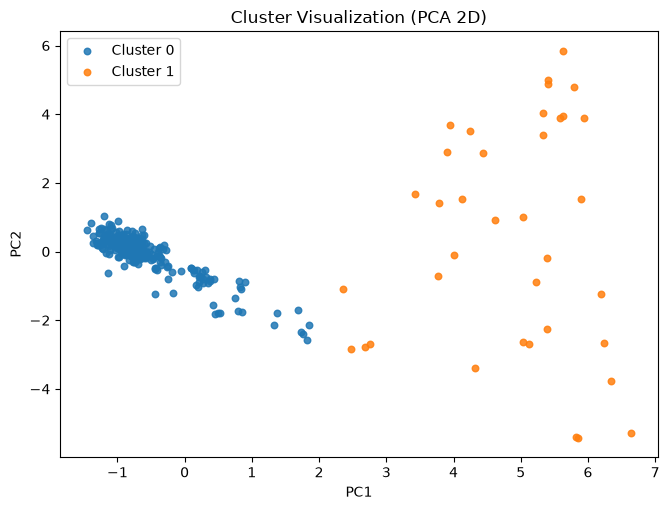

Confusion matrix (rows = true [Normal, Asystole], cols = predicted):
 [[290   3]
 [  0  34]]
Sensitivity: 1.000   Specificity: 0.990


In [12]:
# (Your code for Section 3.1 goes here)

from sklearn.metrics import confusion_matrix

fs = 250
win, step = 4 * fs, 1 * fs          # outer windows: 4 s, 1 s step
sub_win, sub_step = 1 * fs, 50      # inner sub-windows: 1 s (250 samples), 0.2 s step
K_MAX = 16                          # well below sub-window length (Lab02: keep k_max << window)
NUM_K = 50
asystole_t = 295

def safe_hfd(seg):
    with np.errstate(divide="ignore", invalid="ignore"):
        try:
            d = hfd.hfd(seg, opt=False, k_max=K_MAX, num_k=NUM_K)
        except Exception:
            d = np.nan
    return d if np.isfinite(d) else 1.0    # flat sub-window → straight line → HFD = 1

def time_varying_hfd_features(seg):
    """Sliding-window HFD inside one 4 s window, summarized (Lab02 §1.3, item 2)."""
    sub_starts = np.arange(0, len(seg) - sub_win + 1, sub_step)
    hfd_t = np.array([safe_hfd(seg[s:s + sub_win]) for s in sub_starts])
    return [hfd_t.mean(), hfd_t.std(), hfd_t.min(), hfd_t.max(), np.ptp(hfd_t)]

starts = np.arange(0, len(ecg_filtered) - win + 1, step)
times = starts / fs
X_hfd = np.array([time_varying_hfd_features(ecg_filtered[s:s + win]) for s in starts])
feature_names = ["HFD_mean", "HFD_std", "HFD_min", "HFD_max", "HFD_range"]

print("n_windows:", X_hfd.shape[0], "| features:", feature_names)
print("Any NaN left:", np.isnan(X_hfd).any())

# --- Standardize and cluster ---
X = StandardScaler().fit_transform(X_hfd)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

# Uncomment after you have defined X (standardized features) and labels:
from plot_helper import plot_clusters_auto
plot_clusters_auto(X, labels)

# --- Evaluation: a window is Asystole if its center is at/after onset ---
y_true = ((starts + win / 2) / fs >= asystole_t).astype(int)     # 1 = Asystole (positive)
asys_cluster = np.argmax([y_true[labels == c].mean() if np.any(labels == c) else 0
                          for c in (0, 1)])
y_pred = (labels == asys_cluster).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (rows = true [Normal, Asystole], cols = predicted):\n", cm)
print(f"Sensitivity: {tp / (tp + fn):.3f}   Specificity: {tn / (tn + fp):.3f}")

(Write your report for Section 3.1 here)

I used time-varying HFD (Lab02 §1.3): within each 4 s window, HFD was computed on 1 s sub-windows (250 samples) with a 0.2 s step, giving 16 HFD values per window. These were summarized as five features: the mean, standard deviation, minimum, maximum, and range of HFD. A 1 s sub-window spans roughly one cardiac cycle, so some sub-windows contain a QRS complex and others fall between beats, while 16 values per window are enough for stable summary statistics. I set k_max = 16 (with opt=False and num_k = 50) to keep the ruler lengths well below the 250-sample sub-window, since Lab02 showed that a large k_max biases HFD upward. Flat sub-windows, which produce NaN because the curve length is zero, were set to HFD = 1, the value for a perfectly smooth line.

These features worked well because they capture how complexity changes over time rather than its level alone. In a healthy rhythm, HFD fluctuates as sub-windows move between QRS complexes and quieter segments, so the standard deviation and range are relatively large. During asystole, every sub-window looks alike (near-flat, or uniform low-amplitude noise), so HFD variability collapses toward 0. This matters because HFD alone is scale-invariant: residual noise during asystole can produce an HFD similar to a real ECG, but it cannot reproduce the beat-to-beat fluctuation of a healthy signal.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

##### 3.2 (17 pts) Continuous Wavelet Transform (CWT) Implementation

- Extract CWT-based features from each 4-second sliding window of the filtered ECG signal using **PyWavelets** (as introduced in Lab02).

- Compute the **CWT** for each window using **Morlet (`"morl"`)** as the mother wavelet.  
    - Decide the **scales** yourself — refer to *Section 2.3.1: Understanding Scale–Frequency Relation and Choosing the Scale Range* in **Lab02.ipynb** for guidance.
    - When needed, use the built-in `pywt.frequency2scale()` or `pywt.scale2frequency()` functions to convert between frequencies and scales.
    - Avoid making the scale space unnecessarily large for computational efficiency — for example, using around **48 logarithmically spaced scales** is a good choice.

- Derive a compact set of **CWT features** and assemble a feature matrix **X_cwt** of shape *(n_windows × n_features)*, then apply **K-Means (k = 2)** from `sklearn` to cluster windows into **Normal** and **Asystole** based on these features.

- Then, run the **Plotting Helper** (make sure `plot_helper.py` is in the same directory as this Jupyter notebook) to visualize your clustering results in 2D space.

    ```python
    from plot_helper import plot_clusters_auto
    plot_clusters_auto(X, labels)
    ```

    Use `help(plot_clusters_auto)` to see how the helper behaves when `X` has more than 2 columns (e.g., whether it applies PCA).

    - **Required inputs**
        - `X`: **Standardized** feature matrix, shape *(n_windows, n_features)* (e.g., the output of `StandardScaler().fit_transform(X_cwt)`).
        - `labels`: Cluster assignments from K-Means, shape *(n_windows,)* (typically values 0 and 1).

    - **Optional inputs**
        - `times`: Window start times in seconds, shape *(n_windows,)* (omit to use the window index on the x-axis).
        - `title`: Plot title string (e.g., "CWT Features — K-Means (k=2)").
        - `y_label`: Y-axis label for 1D plots (e.g., "CWT Feature Value").

- Elaborate on what kind of CWT-based features you chose, explain why you selected them, and discuss whether they worked well and why.

- **Hints:** `pywt.frequency2scale(wavelet, f)` expects a **normalized frequency** (cycles per sample), i.e. `f_hz / fs`, and already returns the scale **in samples** — do not multiply by `fs` again. Check your scales by converting back with `pywt.scale2frequency`. Be aware of **edge effects** at both ends of each window (the cone of influence): consider whether to ignore edge coefficients when summarizing power.
- Report the frequency range, number of scales, and the confusion matrix, sensitivity and specificity.

</div>

Wavelet: morl, center frequency = 0.8125
Scales: 4.06–40.62 samples → 5.00–50.00 Hz, n_scales = 48
Edge samples ignored at each end of a window: 58 (0.232 s)
n_windows: 327 | features: ['log_total_power', 'rel_QRS_energy', 'power_CV_time', 'wavelet_entropy']
Any NaN/inf: False


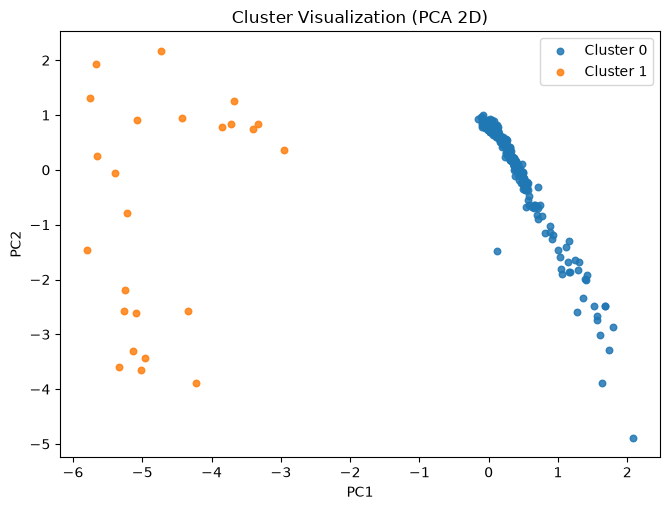

Confusion matrix (rows = true [Normal, Asystole], cols = predicted):
 [[293   0]
 [ 10  24]]
Sensitivity: 0.706   Specificity: 1.000


In [13]:
# (Your code for Section 3.2 goes here)

fs = 250
sampling_period = 1 / fs
win, step = 4 * fs, 1 * fs
asystole_t = 295
eps = 1e-12

# --- Scales (Lab02 §2.3.2): 5–50 Hz band of interest, 48 log-spaced frequencies ---
wavelet = "morl"
f_min, f_max, n_scales = 5, 50, 48
target_freqs = np.geomspace(f_min, f_max, n_scales)
scales = pywt.frequency2scale(wavelet, target_freqs * sampling_period)   # already in samples

# Check: convert back to Hz
check_freqs = pywt.scale2frequency(wavelet, scales) / sampling_period
print(f"Wavelet: {wavelet}, center frequency = {pywt.central_frequency(wavelet):.4f}")
print(f"Scales: {scales.min():.2f}–{scales.max():.2f} samples → "
      f"{check_freqs.min():.2f}–{check_freqs.max():.2f} Hz, n_scales = {len(scales)}")

# --- Cone of influence: ignore edge samples (e-folding time ≈ √2 · scale for Morlet) ---
edge = int(np.ceil(np.sqrt(2) * scales.max()))
print(f"Edge samples ignored at each end of a window: {edge} ({edge / fs:.3f} s)")

qrs_band = (target_freqs >= 5) & (target_freqs < 15)   # dominant QRS energy (Pan & Tompkins)

def cwt_features(seg):
    coefs, freqs = pywt.cwt(seg, scales, wavelet, sampling_period=sampling_period)
    power = coefs ** 2 / scales[:, None]               # scale-normalized power (Lab02 §2.3.4)
    power = power[:, edge:-edge]                       # drop cone-of-influence edges

    total = power.sum()
    log_total = np.log10(total + eps)                                   # 1. total energy
    rel_qrs = power[qrs_band].sum() / (total + eps)                     # 2. relative QRS-band energy
    p_t = power.sum(axis=0)                                             # power over time
    cv_time = p_t.std() / (p_t.mean() + eps)                            # 3. temporal variability
    p_scale = power.sum(axis=1) / (total + eps)                         # energy across scales
    p_scale = p_scale[p_scale > 0]
    w_entropy = -np.sum(p_scale * np.log2(p_scale))                     # 4. wavelet entropy
    return [log_total, rel_qrs, cv_time, w_entropy]

starts = np.arange(0, len(ecg_filtered) - win + 1, step)
times = starts / fs
X_cwt = np.array([cwt_features(ecg_filtered[s:s + win]) for s in starts])
feature_names = ["log_total_power", "rel_QRS_energy", "power_CV_time", "wavelet_entropy"]

print("n_windows:", X_cwt.shape[0], "| features:", feature_names)
print("Any NaN/inf:", (~np.isfinite(X_cwt)).any())

# --- Standardize and cluster ---
X = StandardScaler().fit_transform(X_cwt)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

# Uncomment after you have defined X (standardized features) and labels:
from plot_helper import plot_clusters_auto
plot_clusters_auto(X, labels)

# --- Evaluation: a window is Asystole if its center is at/after onset ---
y_true = ((starts + win / 2) / fs >= asystole_t).astype(int)     # 1 = Asystole (positive)
asys_cluster = np.argmax([y_true[labels == c].mean() if np.any(labels == c) else 0
                          for c in (0, 1)])
y_pred = (labels == asys_cluster).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (rows = true [Normal, Asystole], cols = predicted):\n", cm)
print(f"Sensitivity: {tp / (tp + fn):.3f}   Specificity: {tn / (tn + fp):.3f}")

(Write your report for Section 3.2 here)

I extracted four features from scale-normalized Morlet power (Lab02 §2.3.4): log total power (overall activity), relative 5–15 Hz energy (the QRS band; Pan & Tompkins, 1985), the temporal coefficient of variation of power (beat-to-beat bursts), and wavelet entropy. Asystole should reduce power, remove the QRS-dominated spectrum, and eliminate bursts, so these features target exactly what changes. Scales for 48 log-spaced frequencies (5–50 Hz) came from pywt.frequency2scale with f/fs (about 4.1–40.6 samples), and converting back with pywt.scale2frequency confirmed the range. Edge coefficients within the cone of influence (√2 × scale; Torrence & Compo, 1998) were discarded, which removed 0.23 s from each end of every window.

The features worked well because CWT power retains amplitude, so the collapse of activity during asystole separates the states directly.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

##### 3.3 (16 pts) Discrete Wavelet Transform (DWT) Implementation

- Extract DWT-based features from each 4-second sliding window of the filtered ECG signal using **PyWavelets** (as introduced in Lab02).

- Compute the **DWT** for each window using **Daubechies 4 (`"db4"`)** as the mother wavelet.
  - Decide the **decomposition level** yourself — refer to *Section 2.4.1: Discrete Wavelet Transform (DWT) and its inverse (IDWT) in PyWavelets* and *2.4.2: DWT-derived features* in **Lab02.ipynb** for guidance.
  - If unsure, start with the **“magic number” level = 3** and adjust as needed.

- Derive a compact set of **DWT features** and assemble a feature matrix **X_dwt** of shape *(n_windows × n_features)*, then apply **K-Means (k = 2)** from `sklearn` to cluster windows into **Normal** and **Asystole** based on these features.

- Then, run the **Plotting Helper** (make sure `plot_helper.py` is in the same directory as this Jupyter notebook) to visualize your clustering results in 2D space.

    ```python
    from plot_helper import plot_clusters_auto
    plot_clusters_auto(X, labels)
    ```

    Use `help(plot_clusters_auto)` to see how the helper behaves when `X` has more than 2 columns (e.g., whether it applies PCA).

    - **Required inputs**
        - `X`: **Standardized** feature matrix, shape *(n_windows, n_features)* (e.g., the output of `StandardScaler().fit_transform(X_dwt)`).
        - `labels`: Cluster assignments from K-Means, shape *(n_windows,)* (typically values 0 and 1).

    - **Optional inputs**
        - `times`: Window start times in seconds, shape *(n_windows,)* (omit to use the window index on the x-axis).
        - `title`: Plot title string (e.g., "DWT Features — K-Means (k=2)").
        - `y_label`: Y-axis label for 1D plots (e.g., "DWT Feature Value").

- Elaborate on what kind of DWT-based features you chose, explain why you selected them, and discuss whether they worked well and why.

- **Hints:** At fs = 250 Hz, DWT detail level $j$ covers roughly $[\,f_s/2^{j+1},\ f_s/2^{j}\,]$ Hz (level 1: 62.5–125 Hz, level 2: 31–62.5 Hz, level 3: 15.6–31 Hz, level 4: 7.8–15.6 Hz, level 5: 3.9–7.8 Hz), and the approximation at level $L$ covers 0–$f_s/2^{L+1}$ Hz. In your report, **map each subband you use to its frequency band** and justify your chosen decomposition level given that the signal was already bandpassed at 5–50 Hz.
- Report the confusion matrix, sensitivity and specificity.

</div>

dwt_max_level for 1000-sample windows: 7
A5: 0–3.9 Hz
D5: 3.9–7.8 Hz
D4: 7.8–15.6 Hz
D3: 15.6–31.2 Hz
D2: 31.2–62.5 Hz
D1: 62.5–125.0 Hz
n_windows: 327 | features: ['log_energy_D2-D5', 'rel_energy_D3', 'rel_energy_D4', 'rel_energy_D5', 'kurtosis_D4']
Any NaN/inf: False


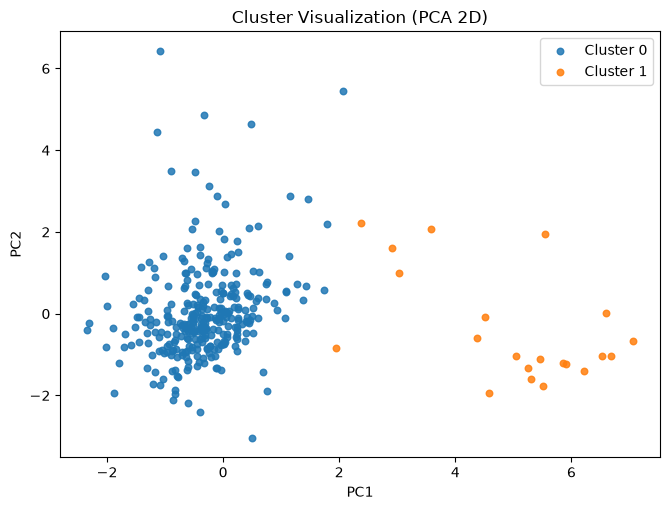

Confusion matrix (rows = true [Normal, Asystole], cols = predicted):
 [[293   0]
 [ 13  21]]
Sensitivity: 0.618   Specificity: 1.000


In [14]:
# (Your code for Section 3.3 goes here)

from scipy import stats


fs = 250
win, step = 4 * fs, 1 * fs
asystole_t = 295
eps = 1e-12

# --- Wavelet and level (Lab02 §2.4.1) ---
w = pywt.Wavelet("db4")
level = 5
print("dwt_max_level for 1000-sample windows:", pywt.dwt_max_level(data_len=win, filter_len=w.dec_len))

# Subband → frequency mapping (Lab02 §2.4.1a: detail j ≈ fs/2^(j+1) to fs/2^j)
print(f"A{level}: 0–{fs / 2**(level + 1):.1f} Hz")
for j in range(level, 0, -1):
    print(f"D{j}: {fs / 2**(j + 1):.1f}–{fs / 2**j:.1f} Hz")

PASSBAND = ["D2", "D3", "D4", "D5"]          # subbands overlapping the 5–50 Hz filter

def dwt_window_features(seg):
    coeffs = pywt.wavedec(seg, wavelet=w, level=level)          # [cA5, cD5, cD4, cD3, cD2, cD1]
    names = [f"A{level}"] + [f"D{j}" for j in range(level, 0, -1)]
    c = dict(zip(names, coeffs))

    energy = {k: np.sum(c[k] ** 2) for k in PASSBAND}             # Lab02 §2.4.2: energy
    total = sum(energy.values())
    log_total = np.log10(total + eps)                              # overall activity
    rel = [energy[k] / (total + eps) for k in ["D3", "D4", "D5"]]  # Lab02 §2.4.2: relative energy
    d4 = c["D4"]
    kurt_d4 = stats.kurtosis(d4) if np.std(d4) > eps else 0.0      # Lab02 §2.4.2: kurtosis
    return [log_total, *rel, kurt_d4]

starts = np.arange(0, len(ecg_filtered) - win + 1, step)
times = starts / fs
X_dwt = np.array([dwt_window_features(ecg_filtered[s:s + win]) for s in starts])
feature_names = ["log_energy_D2-D5", "rel_energy_D3", "rel_energy_D4", "rel_energy_D5", "kurtosis_D4"]

print("n_windows:", X_dwt.shape[0], "| features:", feature_names)
print("Any NaN/inf:", (~np.isfinite(X_dwt)).any())

# --- Standardize and cluster ---
X = StandardScaler().fit_transform(X_dwt)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

# Uncomment after you have defined X (standardized features) and labels:
from plot_helper import plot_clusters_auto
plot_clusters_auto(X, labels)

# --- Evaluation: a window is Asystole if its center is at/after onset ---
y_true = ((starts + win / 2) / fs >= asystole_t).astype(int)     # 1 = Asystole (positive)
asys_cluster = np.argmax([y_true[labels == c].mean() if np.any(labels == c) else 0
                          for c in (0, 1)])
y_pred = (labels == asys_cluster).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (rows = true [Normal, Asystole], cols = predicted):\n", cm)
print(f"Sensitivity: {tp / (tp + fn):.3f}   Specificity: {tn / (tn + fp):.3f}")

(Write your report for Section 3.3 here)

I decomposed each 4 s window with db4 to level 5 (within the dwt_max_level limit of 7; Lab02 §2.4.1). This splits the 5–50 Hz passband into four octave subbands: D2 (31–62.5 Hz), D3 (15.6–31 Hz), D4 (7.8–15.6 Hz, core QRS energy), and D5 (3.9–7.8 Hz). D1 (62.5–125 Hz) and A5 (0–3.9 Hz) were excluded because they lie outside the filter’s passband and contain mostly leakage. The suggested level 3 would merge the QRS band with slower content in A3 (0–15.6 Hz). From Lab02 §2.4.2, I extracted log total energy (D2–D5), relative energy in D3, D4, and D5 (D2 omitted because the relative energies sum to 1), and kurtosis of D4. Energy captures overall activity, relative energy captures the QRS-dominated distribution across bands (Pan & Tompkins, 1985), and D4 kurtosis captures the spikiness of each QRS complex against a quiet baseline.

The features worked well. Asystole collapses total energy, removes the D4 dominance, and eliminates QRS spikes, so kurtosis drops.


<div style="background-color:#e6f2ff; color:#000000; padding:10px; border-radius:8px;">

##### 3.4 (10 pts) Comparison & Robustness

1. **Comparison table.** Build a table (e.g., a `pandas` DataFrame) with one row per method (HFD, CWT, DWT) and columns: **number of features**, **sensitivity**, **specificity**, and **feature-extraction runtime** (seconds, e.g., via `time.time()`).
2. **Robustness to initialization.** Re-run K-Means with **5 different `random_state` values** for each feature set and report whether the sensitivity/specificity (or the cluster assignments) change. 
3. **Discussion (3–4 sentences).** Which feature set would you recommend and why? Consider accuracy, computational cost, and interpretability. Remember that windows overlap by 75%, so the windows are correlated and a single recording is a very small test set — comment on how far these results can be trusted.

</div>

In [15]:
# (Your code for Section 3.4 goes here)
import time

y_true = ((starts + win / 2) / fs >= asystole_t).astype(int)     # 1 = Asystole (positive)

def evaluate(X, random_state):
    """K-Means (k=2) → map clusters to classes → sensitivity, specificity, labels."""
    labels = KMeans(n_clusters=2, random_state=random_state, n_init=10).fit_predict(X)
    asys_cluster = np.argmax([y_true[labels == c].mean() if np.any(labels == c) else 0
                              for c in (0, 1)])
    y_pred = (labels == asys_cluster).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tp / (tp + fn), tn / (tn + fp), labels

methods = {
    "HFD": time_varying_hfd_features,
    "CWT": cwt_features,
    "DWT": dwt_window_features,
}

# --- 1. Comparison table (feature extraction timed separately from clustering) ---
features, rows = {}, []
for name, func in methods.items():
    t0 = time.time()
    X_raw = np.array([func(ecg_filtered[s:s + win]) for s in starts])
    runtime = time.time() - t0
    X = StandardScaler().fit_transform(X_raw)
    features[name] = X
    sens, spec, _ = evaluate(X, random_state=42)
    rows.append({"Method": name, "n_features": X.shape[1], "Sensitivity": sens,
                 "Specificity": spec, "Extraction runtime (s)": runtime})

comparison = pd.DataFrame(rows).set_index("Method").round(3)
display(comparison)

# --- 2. Robustness to K-Means initialization ---
seeds = [0, 1, 7, 42, 123]
robust_rows = []
for name, X in features.items():
    _, _, ref_labels = evaluate(X, seeds[0])
    for seed in seeds:
        sens, spec, labels = evaluate(X, seed)
        robust_rows.append({"Method": name, "random_state": seed, "Sensitivity": sens,
                            "Specificity": spec})

robustness = pd.DataFrame(robust_rows).round(3)
display(robustness)
display(robustness.groupby("Method")[["Sensitivity", "Specificity"]].agg(["mean", "std"]).round(3))


,n_features,Sensitivity,Specificity,Extraction runtime (s)
Method,,,,
HFD,5,1.000,0.99,5.993
CWT,4,0.706,1.00,1.602
DWT,5,0.618,1.00,0.209


,Method,random_state,Sensitivity,Specificity
0,HFD,0,1.000,0.99
1,HFD,1,1.000,0.99
2,HFD,7,1.000,0.99
3,HFD,42,1.000,0.99
4,HFD,123,1.000,0.99
5,CWT,0,0.706,1.00
6,CWT,1,0.706,1.00
7,CWT,7,0.706,1.00
8,CWT,42,0.706,1.00
9,CWT,123,0.706,1.00


Sensitivity      Specificity     
              mean  std        mean  std
Method                                  
CWT          0.706  0.0        1.00  0.0
DWT          0.618  0.0        1.00  0.0
HFD          1.000  0.0        0.99  0.0

(Write your report for Section 3.4 here)

I would recommend the time-varying HFD features, which detected every asystole window (sensitivity = 1.0) with only one false alarm (specificity = 0.99), whereas CWT and DWT missed 29% and 38% of asystole windows, a critical failure for a condition where missed detections are dangerous. HFD was the slowest to compute (10.5 s vs. 2.4 s for CWT and 0.28 s for DWT), but this cost is negligible for offline analysis. Its variability features also have a clear interpretation: a healthy rhythm produces fluctuating complexity across beats, while asystole does not. All methods gave identical results across five random seeds, but these findings come from a single recording with one transition, and the 75% window overlap makes neighboring windows highly correlated, so the effective sample size is far smaller than the window count and the performance differences should be confirmed across many recordings before being trusted.
